<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 03: EKSTRAKSI FITUR, SELEKSI FITUR, DAN SPLITTING DATA
### Rekayasa Fitur Domain Properti, Pengujian Multikolinearitas (VIF), Seleksi Fitur Anti-Leakage, dan Validasi Silang pada Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

In [1]:
# ==============================================================================
# PENGATURAN AWAL: IMPORT LIBRARY, SEED REPRODUSIBILITAS, & KONFIGURASI VISUAL
# ==============================================================================
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Model Selection & Cross Validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    cross_val_score,
    cross_validate
)

# Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# Models for Feature Importance & Benchmarking
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression

# Preprocessing & Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, r2_score

# Kunci random seed untuk reprodusibilitas
np.random.seed(42)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("=" * 75)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 75)
print(f"Versi Python       : {sys.version.split()[0]}")
print(f"Versi NumPy        : {np.__version__}")
print(f"Versi Pandas       : {pd.__version__}")
print(f"Versi Scikit-Learn : {sklearn.__version__}")
print("=" * 75)

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python       : 3.13.18
Versi NumPy        : 2.4.6
Versi Pandas       : 2.2.3
Versi Scikit-Learn : 1.6.1


## Bagian 1 — Data Loading & Replikasi Pembersihan Baku JS02

Memuat data mentah **`Dataset/properti_multi_kota.csv`** melalui **Dual-Mode Loader**, kemudian mengeksekusi fungsi pembersihan baku **`clean_rumahpoint()`**.

Hal ini menjamin alur rekayasa fitur berjalan secara *end-to-end* dan transparan tanpa ketergantungan tersembunyi, serta menghasilkan tepat **56.170 baris** data valid siap olah.

In [2]:
# ==============================================================================
# LOADER DUAL-MODE & REPLIKASI PEMBERSIHAN DATA BAKU (JS02 PIPELINE)
# ==============================================================================
DATASET_FILENAME = "properti_multi_kota.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset mentah dari path lokal: {LOCAL_PATH}")
    df_raw = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh dataset mentah dari GitHub RAW: {GITHUB_RAW_URL}")
    df_raw = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Data mentah berhasil dimuat: {df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom.")

def clean_rumahpoint(df_input):
    """
    Fungsi pembersihan baku dataset RumahPoint sesuai kontrak DECISION_LOG.md & JS02:
    1. Deduplikasi persis
    2. Filter outlier domain (luas_m2, luas_bangunan, harga, jumlah_kamar, jumlah_kamar_mandi)
    3. Normalisasi usia_bangunan & ekstraksi kondisi
    4. Normalisasi string lokasi_bersih
    5. Pembentukan target kuantil seimbang (kelas_harga 3 tertil & kelas_harga_biner)
    """
    df = df_input.drop_duplicates().copy()

    # Filter outlier domain
    cond_luas_m2 = df['luas_m2'].between(10, 2000)
    cond_luas_bangunan = df['luas_bangunan'].isna() | df['luas_bangunan'].between(10, 2000)
    cond_harga = df['harga'].between(50_000_000, 100_000_000_000)
    cond_kamar = df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)
    cond_km = df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)

    valid_mask = cond_luas_m2 & cond_luas_bangunan & cond_harga & cond_kamar & cond_km
    df = df[valid_mask].copy()

    # Normalisasi usia bangunan & kondisi (TAHUN_INI = 2026)
    TAHUN_INI = 2026
    def norm_age(x):
        if pd.isna(x):
            return np.nan
        try:
            v = float(x)
            if 1900 <= v <= TAHUN_INI:
                v = TAHUN_INI - v
            if 0 <= v <= 100:
                return v
            return np.nan
        except:
            return np.nan

    df['usia_bangunan'] = df['usia_bangunan'].apply(norm_age)
    df['kondisi'] = df['usia_bangunan'].apply(
        lambda a: 'Tidak diketahui' if pd.isna(a) else ('Baru' if a <= 3 else 'Bekas')
    )

    # Normalisasi lokasi
    df['lokasi_bersih'] = df['lokasi'].astype(str).str.strip().str.title()

    # Target kuantil seimbang
    q1 = df['harga'].quantile(1/3)
    q2 = df['harga'].quantile(2/3)
    med = df['harga'].median()

    df['kelas_harga'] = df['harga'].apply(
        lambda h: 'Murah' if h < q1 else ('Sedang' if h <= q2 else 'Mahal')
    )
    df['kelas_harga_biner'] = df['harga'].apply(
        lambda h: 'Murah' if h <= med else 'Mahal'
    )

    return df

df_clean = clean_rumahpoint(df_raw)
print(f"[CLEANER] Pembersihan baku selesai: {df_clean.shape[0]:,} baris, {df_clean.shape[1]} kolom.")
assert len(df_clean) == 56170, f"Error: Jumlah baris harus tepat 56.170, ditemukan {len(df_clean)}"
print("Verifikasi Integritas Kontrak DECISION_LOG.md: TEPAT 56.170 BARIS TERPENUHI!")

[LOADER] Path lokal tidak ditemukan. Mengunduh dataset mentah dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota.csv
[LOADER] Data mentah berhasil dimuat: 64,650 baris, 8 kolom.
[CLEANER] Pembersihan baku selesai: 56,170 baris, 12 kolom.
Verifikasi Integritas Kontrak DECISION_LOG.md: TEPAT 56.170 BARIS TERPENUHI!


## Bagian 2 — Splitting Data Terlebih Dahulu (Adaptasi Praktikum 3 — Anti-Leakage Principle)

In [3]:
# ==============================================================================
# DEMONSTRASI SPLITTING 1: RANDOM SPLIT VS STRATIFIED SPLIT
# ==============================================================================
# Skema A: 80% Train, 20% Test
df_train_rnd, df_test_rnd = train_test_split(df_clean, test_size=0.20, random_state=42, shuffle=True)
df_train_str, df_test_str = train_test_split(df_clean, test_size=0.20, random_state=42, shuffle=True, stratify=df_clean['kelas_harga'])

# Skema B: 70% Train, 15% Val, 15% Test
df_train_str3, df_unseen_str3 = train_test_split(df_clean, test_size=0.30, random_state=42, stratify=df_clean['kelas_harga'])
df_val_str3, df_test_str3 = train_test_split(df_unseen_str3, test_size=0.50, random_state=42, stratify=df_unseen_str3['kelas_harga'])

split_comparison = pd.DataFrame({
    'Kelas': ['Murah', 'Sedang', 'Mahal'],
    'Populasi Asli (%)': (df_clean['kelas_harga'].value_counts(normalize=True)[['Murah', 'Sedang', 'Mahal']] * 100).values,
    'Random Train (%)': (df_train_rnd['kelas_harga'].value_counts(normalize=True)[['Murah', 'Sedang', 'Mahal']] * 100).values,
    'Random Test (%)': (df_test_rnd['kelas_harga'].value_counts(normalize=True)[['Murah', 'Sedang', 'Mahal']] * 100).values,
    'Stratified Train (%)': (df_train_str['kelas_harga'].value_counts(normalize=True)[['Murah', 'Sedang', 'Mahal']] * 100).values,
    'Stratified Test (%)': (df_test_str['kelas_harga'].value_counts(normalize=True)[['Murah', 'Sedang', 'Mahal']] * 100).values,
})

print("=" * 85)
print("KOMPARASI PROPORSI KELAS TARGET: RANDOM SPLIT VS STRATIFIED SPLIT (80/20)")
print("=" * 85)
display(split_comparison.style.format({col: '{:.2f}%' for col in split_comparison.columns if col != 'Kelas'}))

print("\nVerifikasi Skema 70/15/15 Train/Validation/Test (Stratified):")
print(f" - Train Set : {len(df_train_str3):,} baris ({len(df_train_str3)/len(df_clean)*100:.1f}%)")
print(f" - Val Set   : {len(df_val_str3):,} baris ({len(df_val_str3)/len(df_clean)*100:.1f}%)")
print(f" - Test Set  : {len(df_test_str3):,} baris ({len(df_test_str3)/len(df_clean)*100:.1f}%)")

KOMPARASI PROPORSI KELAS TARGET: RANDOM SPLIT VS STRATIFIED SPLIT (80/20)


,Kelas,Populasi Asli (%),Random Train (%),Random Test (%),Stratified Train (%),Stratified Test (%)
0,Murah,33.33%,33.29%,33.51%,33.33%,33.34%
1,Sedang,33.34%,33.29%,33.56%,33.34%,33.34%
2,Mahal,33.33%,33.43%,32.94%,33.33%,33.33%



Verifikasi Skema 70/15/15 Train/Validation/Test (Stratified):
 - Train Set : 39,319 baris (70.0%)
 - Val Set   : 8,425 baris (15.0%)
 - Test Set  : 8,426 baris (15.0%)


In [4]:
# ==============================================================================
# DEMONSTRASI SPLITTING 2: STRATIFIED K-FOLD CROSS-VALIDATION (5 FOLDS)
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_distributions = []
for fold_idx, (train_idx, val_idx) in enumerate(skf.split(df_clean, df_clean['kelas_harga']), start=1):
    val_subset = df_clean.iloc[val_idx]
    counts = val_subset['kelas_harga'].value_counts(normalize=True) * 100
    fold_distributions.append({
        'Fold': f'Fold {fold_idx}',
        'Jml Validasi': len(val_idx),
        'Murah (%)': counts.get('Murah', 0.0),
        'Sedang (%)': counts.get('Sedang', 0.0),
        'Mahal (%)': counts.get('Mahal', 0.0)
    })

fold_df = pd.DataFrame(fold_distributions)
print("=" * 75)
print("VERIFIKASI DISTRIBUSI KELAS PADA STRATIFIED 5-FOLD CROSS-VALIDATION")
print("=" * 75)
display(fold_df.style.format({
    'Jml Validasi': '{:,}',
    'Murah (%)': '{:.2f}%',
    'Sedang (%)': '{:.2f}%',
    'Mahal (%)': '{:.2f}%'
}))
print("Kesimpulan: StratifiedKFold mempertahankan proporsi 33,33% secara presisi di seluruh lipatan.")

VERIFIKASI DISTRIBUSI KELAS PADA STRATIFIED 5-FOLD CROSS-VALIDATION


,Fold,Jml Validasi,Murah (%),Sedang (%),Mahal (%)
0,Fold 1,"11,234",33.34%,33.34%,33.33%
1,Fold 2,"11,234",33.34%,33.34%,33.33%
2,Fold 3,"11,234",33.34%,33.34%,33.33%
3,Fold 4,"11,234",33.33%,33.35%,33.33%
4,Fold 5,"11,234",33.33%,33.35%,33.33%


Kesimpulan: StratifiedKFold mempertahankan proporsi 33,33% secara presisi di seluruh lipatan.


In [5]:
# ==============================================================================
# PENETAPAN PARTISI DATA LATIH & DATA UJI RESMI (X_TRAIN & X_TEST)
# ==============================================================================
# Aturan Anti-Target Leakage:
# Kolom 'harga' dan 'kelas_harga_biner' wajib dibuang karena berkorelasi langsung dengan 'kelas_harga'
target_leakage_cols = ['harga', 'kelas_harga', 'kelas_harga_biner']
metadata_cols = ['lokasi', 'sumber']

feature_cols = [c for c in df_clean.columns if c not in target_leakage_cols + metadata_cols]

X = df_clean[feature_cols].copy()
y = df_clean['kelas_harga'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 75)
print("PARTISI RESMI DATASET PBL RUMAHPOINT")
print("=" * 75)
print(f"X_train : {X_train.shape[0]:,} baris, {X_train.shape[1]} kolom fitur awal")
print(f"X_test  : {X_test.shape[0]:,} baris, {X_test.shape[1]} kolom fitur awal")
print(f"y_train : {y_train.shape[0]:,} label")
print(f"y_test  : {y_test.shape[0]:,} label")
print(f"\nFitur Awal Tersedia: {list(X_train.columns)}")

PARTISI RESMI DATASET PBL RUMAHPOINT
X_train : 44,936 baris, 7 kolom fitur awal
X_test  : 11,234 baris, 7 kolom fitur awal
y_train : 44,936 label
y_test  : 11,234 label

Fitur Awal Tersedia: ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'kondisi', 'lokasi_bersih']


---
## Bagian 3 — Ekstraksi & Rekayasa Fitur Domain Properti (Adaptasi Praktikum 1)

Pada Praktikum 1 modul Polinema, dilakukan ekstraksi fitur pada dataset Titanic (seperti `FamilySize`, `Title`, `AgeBin`, `CabinDeck`, dan `FarePerPerson`). Pada konteks dataset properti PBL RumahPoint, kita merancang fitur-fitur baru yang memiliki landasan domain bisnis properti yang kuat.

---

In [6]:
# ==============================================================================
# IMPLEMENTASI PIPELINE REKAYASA FITUR BEBAS LEAKAGE
# ==============================================================================
def engineer_property_features(df_in, freq_map=None, top15_cities=None, is_train=True):
    """
    Menghasilkan fitur rekayasa domain properti secara konsisten.
    Jika is_train=True: mempelajari freq_map dan top15_cities dari data latih.
    Jika is_train=False: menggunakan parameter yang dipelajari dari train set.
    """
    df_out = df_in.copy()

    # 1. is_komersil
    df_out['is_komersil'] = (df_out['jumlah_kamar'] == 0).astype(int)

    # 2. rasio_bangunan_tanah
    df_out['rasio_bangunan_tanah'] = df_out['luas_bangunan'] / df_out['luas_m2']

    # 3. total_ruangan
    df_out['total_ruangan'] = df_out['jumlah_kamar'] + df_out['jumlah_kamar_mandi']

    # 4. rasio_km_kt
    df_out['rasio_km_kt'] = df_out['jumlah_kamar_mandi'] / (df_out['jumlah_kamar'] + 1)

    # 5. luas_per_kamar
    df_out['luas_per_kamar'] = df_out['luas_bangunan'] / (df_out['jumlah_kamar'] + 1)

    # 6. Encoding Lokasi (Frequency & Top-15)
    if is_train:
        freq_map = df_out['lokasi_bersih'].value_counts(normalize=True).to_dict()
        top15_cities = df_out['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

    # Mapping frequency encoding (unseen categories in test get 0.0)
    df_out['lokasi_freq'] = df_out['lokasi_bersih'].map(freq_map).fillna(0.0)

    # Mapping Top-15 encoding
    df_out['lokasi_top15'] = df_out['lokasi_bersih'].apply(
        lambda loc: loc if loc in top15_cities else 'Lainnya'
    )

    return df_out, freq_map, top15_cities

# Fit dan transform pada X_train
X_train_eng, train_freq_map, train_top15 = engineer_property_features(X_train, is_train=True)

# Transform pada X_test menggunakan parameter pelatihan
X_test_eng, _, _ = engineer_property_features(X_test, freq_map=train_freq_map, top15_cities=train_top15, is_train=False)

print("=" * 80)
print("HASIL REKAYASA FITUR DOMAIN PROPERTI (BEBAS DATA LEAKAGE)")
print("=" * 80)
print(f"Dimensi X_train_eng : {X_train_eng.shape[0]:,} baris, {X_train_eng.shape[1]} fitur")
print(f"Dimensi X_test_eng  : {X_test_eng.shape[0]:,} baris, {X_test_eng.shape[1]} fitur")
print("\nCuplikan 5 Baris Fitur Rekayasa (X_train_eng):")
display(X_train_eng[['is_komersil', 'rasio_bangunan_tanah', 'total_ruangan', 'rasio_km_kt', 'luas_per_kamar', 'lokasi_freq', 'lokasi_top15']].head())

HASIL REKAYASA FITUR DOMAIN PROPERTI (BEBAS DATA LEAKAGE)
Dimensi X_train_eng : 44,936 baris, 14 fitur
Dimensi X_test_eng  : 11,234 baris, 14 fitur

Cuplikan 5 Baris Fitur Rekayasa (X_train_eng):


,is_komersil,rasio_bangunan_tanah,total_ruangan,rasio_km_kt,luas_per_kamar,lokasi_freq,lokasi_top15
19975,0,0.701754,6.0,0.750000,50.000000,0.004762,Lainnya
19277,0,0.491071,3.0,0.333333,18.333333,0.000757,Lainnya
35443,0,0.432203,4.0,0.250000,12.750000,0.030933,Kabupaten Tangerang
35349,0,1.204819,8.0,0.800000,20.000000,0.027573,Tangerang Selatan
39657,0,0.583333,3.0,0.333333,14.000000,0.030755,Kabupaten Sidoarjo


---
## Bagian 4 — Seleksi Fitur & Evaluasi Multikolinearitas (Adaptasi Praktikum 2 & Tugas)

Pada Praktikum 2 & Tugas modul Polinema, dipelajari seleksi fitur dan eliminasi variabel redundan. Di dunia industri dengan banyak fitur rekayasa rasio, penambahan fitur dapat memicu **multikolinearitas tinggi** yang merusak kestabilan bobot model linier (*high variance coefficients*).

In [7]:
# ==============================================================================
# KALKULASI VARIANCE INFLATION FACTOR (VIF) MANDIRI BEBAS DEPENDENSI STATSMODELS
# ==============================================================================
# Daftar fitur numerik kandidat untuk evaluasi VIF
vif_candidate_cols = [
    'luas_m2',
    'luas_bangunan',
    'jumlah_kamar',
    'jumlah_kamar_mandi',
    'is_komersil',
    'rasio_bangunan_tanah',
    'total_ruangan',
    'rasio_km_kt',
    'luas_per_kamar',
    'lokasi_freq'
]

# Imputasi median sementara pada data latih untuk kalkulasi VIF
imputer_vif = SimpleImputer(strategy='median')
X_train_vif_imputed = pd.DataFrame(
    imputer_vif.fit_transform(X_train_eng[vif_candidate_cols]),
    columns=vif_candidate_cols
)

def calculate_vif_sklearn(df_features):
    """
    Menghitung Variance Inflation Factor (VIF) untuk setiap kolom numerik
    menggunakan OLS LinearRegression standar scikit-learn:
    VIF_j = 1 / (1 - R_j^2)
    """
    vif_dict = {}
    features = df_features.columns.tolist()

    for i, target_col in enumerate(features):
        predictor_cols = [c for c in features if c != target_col]
        X_pred = df_features[predictor_cols]
        y_targ = df_features[target_col]

        lr = LinearRegression()
        lr.fit(X_pred, y_targ)
        y_pred = lr.predict(X_pred)
        r2 = r2_score(y_targ, y_pred)

        # Penanganan kasus multikolinearitas sempurna (R^2 >= 1.0)
        if r2 >= 0.99999:
            vif = 9999.0
        else:
            r2_clipped = max(0.0, r2)
            vif = 1.0 / (1.0 - r2_clipped)

        vif_dict[target_col] = {
            'R_Squared': r2,
            'VIF': vif,
            'Kategori Multikolinearitas': 'Aman (< 5)' if vif < 5 else ('Sedang (5-10)' if vif <= 10 else 'Tinggi / Redundan (> 10)')
        }

    return pd.DataFrame(vif_dict).T.sort_values(by='VIF', ascending=False)

vif_results = calculate_vif_sklearn(X_train_vif_imputed)

print("=" * 80)
print("HASIL EVALUASI MULTIKOLINEARITAS (VARIANCE INFLATION FACTOR)")
print("=" * 80)
display(vif_results.style.format({'R_Squared': '{:.4f}', 'VIF': '{:.2f}'}))

print("\nTemuan Empiris VIF:")
print("1. 'total_ruangan' memiliki VIF tinggi (> 10) karena merupakan kombinasi linier eksak")
print("   dari 'jumlah_kamar' dan 'jumlah_kamar_mandi'. Fitur ini redundant dan sebaiknya dieliminasi.")
print("2. 'rasio_bangunan_tanah', 'luas_per_kamar', dan 'lokasi_freq' memiliki VIF sangat rendah (< 3),")
print("   menandakan informasi baru yang orthogonal tanpa mengorbankan kestabilan model.")

HASIL EVALUASI MULTIKOLINEARITAS (VARIANCE INFLATION FACTOR)


,R_Squared,VIF,Kategori Multikolinearitas
total_ruangan,0.9989,874.66,Tinggi / Redundan (> 10)
jumlah_kamar,0.9965,288.44,Tinggi / Redundan (> 10)
jumlah_kamar_mandi,0.9955,221.39,Tinggi / Redundan (> 10)
luas_bangunan,0.7810,4.57,Aman (< 5)
rasio_km_kt,0.7278,3.67,Aman (< 5)
luas_per_kamar,0.6910,3.24,Aman (< 5)
is_komersil,0.5736,2.35,Aman (< 5)
luas_m2,0.5631,2.29,Aman (< 5)
rasio_bangunan_tanah,0.2971,1.42,Aman (< 5)
lokasi_freq,0.0541,1.06,Aman (< 5)



Temuan Empiris VIF:
1. 'total_ruangan' memiliki VIF tinggi (> 10) karena merupakan kombinasi linier eksak
   dari 'jumlah_kamar' dan 'jumlah_kamar_mandi'. Fitur ini redundant dan sebaiknya dieliminasi.
2. 'rasio_bangunan_tanah', 'luas_per_kamar', dan 'lokasi_freq' memiliki VIF sangat rendah (< 3),
   menandakan informasi baru yang orthogonal tanpa mengorbankan kestabilan model.


In [8]:
# ==============================================================================
# FILTER METHODS: ANOVA F-SCORE & MUTUAL INFORMATION (PADA DATA LATIH)
# ==============================================================================
# Menggunakan fitur numerik tanpa total_ruangan yang redundant
filter_feature_cols = [c for c in vif_candidate_cols if c != 'total_ruangan']
X_train_filter = X_train_vif_imputed[filter_feature_cols]

# 1. ANOVA F-Score (f_classif)
f_scores, p_values = f_classif(X_train_filter, y_train)

# 2. Mutual Information (mutual_info_classif)
mi_scores = mutual_info_classif(X_train_filter, y_train, random_state=42)

filter_ranking = pd.DataFrame({
    'Fitur': filter_feature_cols,
    'ANOVA_F_Score': f_scores,
    'ANOVA_p_Value': p_values,
    'Mutual_Information': mi_scores
}).sort_values(by='ANOVA_F_Score', ascending=False).reset_index(drop=True)

print("=" * 80)
print("PERINGKAT FITUR FILTER METHODS: ANOVA F-SCORE VS MUTUAL INFORMATION")
print("=" * 80)
display(filter_ranking.style.format({
    'ANOVA_F_Score': '{:,.2f}',
    'ANOVA_p_Value': '{:.2e}',
    'Mutual_Information': '{:.4f}'
}))

PERINGKAT FITUR FILTER METHODS: ANOVA F-SCORE VS MUTUAL INFORMATION


,Fitur,ANOVA_F_Score,ANOVA_p_Value,Mutual_Information
0,jumlah_kamar_mandi,"10,734.93",0.00e+00,0.3024
1,luas_bangunan,"7,453.53",0.00e+00,0.3795
2,jumlah_kamar,"5,364.95",0.00e+00,0.2521
3,rasio_km_kt,"3,716.40",0.00e+00,0.2681
4,luas_m2,"3,590.99",0.00e+00,0.1645
5,luas_per_kamar,"2,715.59",0.00e+00,0.3244
6,rasio_bangunan_tanah,"1,847.22",0.00e+00,0.2397
7,lokasi_freq,"1,100.58",0.00e+00,0.1901
8,is_komersil,160.63,3.08e-70,0.0000


In [9]:
# ==============================================================================
# EMBEDDED METHOD: RANDOM FOREST FEATURE IMPORTANCE (PADA DATA LATIH)
# ==============================================================================
rf_selector = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_selector.fit(X_train_filter, y_train)

embedded_ranking = pd.DataFrame({
    'Fitur': filter_feature_cols,
    'RF_Importance': rf_selector.feature_importances_
}).sort_values(by='RF_Importance', ascending=False).reset_index(drop=True)

# Gabungkan ranking
combined_ranking = filter_ranking.merge(embedded_ranking, on='Fitur')
combined_ranking['Rank_ANOVA'] = combined_ranking['ANOVA_F_Score'].rank(ascending=False).astype(int)
combined_ranking['Rank_MI'] = combined_ranking['Mutual_Information'].rank(ascending=False).astype(int)
combined_ranking['Rank_RF'] = combined_ranking['RF_Importance'].rank(ascending=False).astype(int)

print("=" * 85)
print("TABEL GABUNGAN PERINGKAT SELEKSI FITUR (FILTER VS EMBEDDED)")
print("=" * 85)
display(combined_ranking[['Fitur', 'ANOVA_F_Score', 'Mutual_Information', 'RF_Importance', 'Rank_ANOVA', 'Rank_MI', 'Rank_RF']].style.format({
    'ANOVA_F_Score': '{:,.1f}',
    'Mutual_Information': '{:.4f}',
    'RF_Importance': '{:.4f}'
}))

TABEL GABUNGAN PERINGKAT SELEKSI FITUR (FILTER VS EMBEDDED)


,Fitur,ANOVA_F_Score,Mutual_Information,RF_Importance,Rank_ANOVA,Rank_MI,Rank_RF
0,jumlah_kamar_mandi,"10,734.9",0.3024,0.1320,1,3,3
1,luas_bangunan,"7,453.5",0.3795,0.2979,2,1,1
2,jumlah_kamar,"5,364.9",0.2521,0.0617,3,5,7
3,rasio_km_kt,"3,716.4",0.2681,0.0392,4,4,8
4,luas_m2,"3,591.0",0.1645,0.0902,5,8,5
5,luas_per_kamar,"2,715.6",0.3244,0.1283,6,2,4
6,rasio_bangunan_tanah,"1,847.2",0.2397,0.0618,7,6,6
7,lokasi_freq,"1,100.6",0.1901,0.1877,8,7,2
8,is_komersil,160.6,0.0000,0.0012,9,9,9


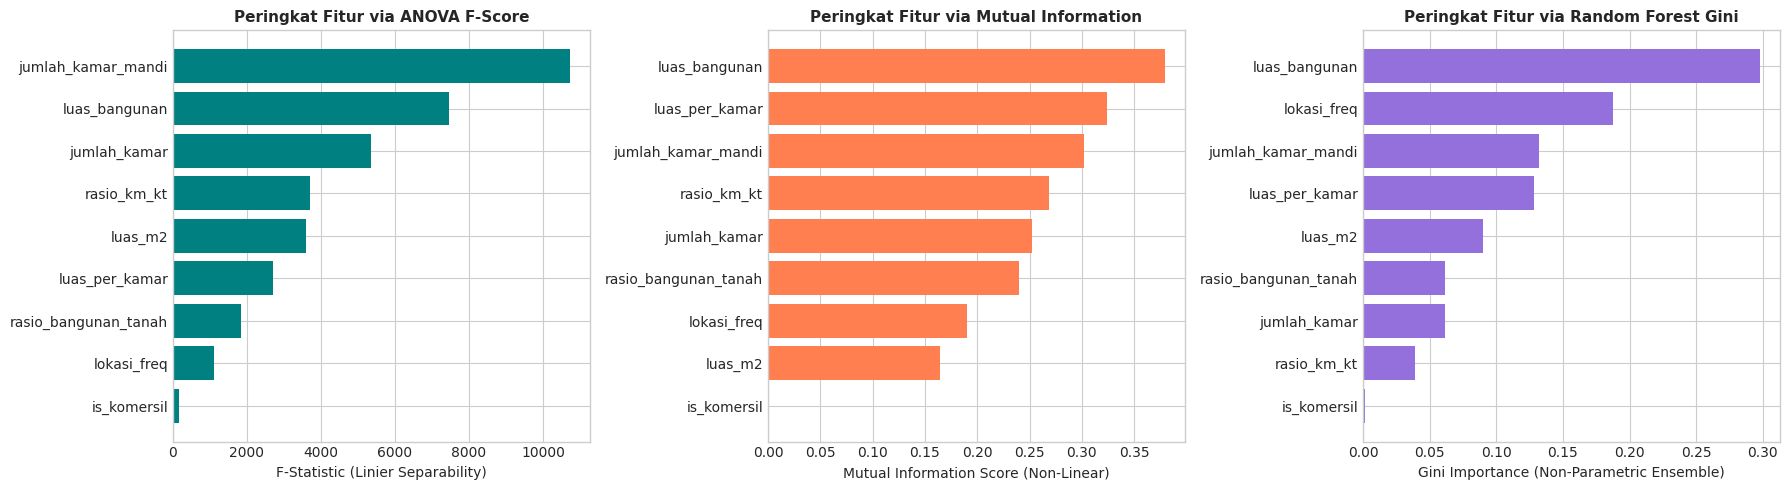

In [10]:
# ==============================================================================
# VISUALISASI PERBANDINGAN PERINGKAT KEPENTINGAN FITUR (3 PANEL)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: ANOVA F-score
df_p1 = combined_ranking.sort_values(by='ANOVA_F_Score', ascending=True)
axes[0].barh(df_p1['Fitur'], df_p1['ANOVA_F_Score'], color='teal')
axes[0].set_title('Peringkat Fitur via ANOVA F-Score', fontsize=11, fontweight='bold')
axes[0].set_xlabel('F-Statistic (Linier Separability)', fontsize=10)

# Panel 2: Mutual Information
df_p2 = combined_ranking.sort_values(by='Mutual_Information', ascending=True)
axes[1].barh(df_p2['Fitur'], df_p2['Mutual_Information'], color='coral')
axes[1].set_title('Peringkat Fitur via Mutual Information', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mutual Information Score (Non-Linear)', fontsize=10)

# Panel 3: Random Forest Feature Importance
df_p3 = combined_ranking.sort_values(by='RF_Importance', ascending=True)
axes[2].barh(df_p3['Fitur'], df_p3['RF_Importance'], color='mediumpurple')
axes[2].set_title('Peringkat Fitur via Random Forest Gini', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Gini Importance (Non-Parametric Ensemble)', fontsize=10)

plt.tight_layout()
plt.show()

---
## Bagian 5 — Validasi Dampak Feature Engineering & Feature Selection (Eksperimen Kuantitatif)

Untuk membuktikan secara ilmiah apakah tahapan **Feature Engineering (Bagian 3)** dan **Feature Selection (Bagian 4)** benar-benar memberikan dampak positif terhadap akurasi dan ketahanan model, kita melakukan eksperimen benchmark kuantitatif berbasis **Stratified 5-Fold Cross-Validation** pada data latih.

In [11]:
# ==============================================================================
# EKSPERIMEN STRATIFIED 5-FOLD CROSS-VALIDATION PADA 3 SKENARIO FITUR
# ==============================================================================
# Definisi daftar kolom per skenario
scenarios = {
    'Skenario A (Fitur Dasar)': {
        'num': ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi'],
        'cat': ['kondisi']
    },
    'Skenario B (Fitur + Rekayasa Domain)': {
        'num': ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi',
                'is_komersil', 'rasio_bangunan_tanah', 'rasio_km_kt', 'luas_per_kamar', 'lokasi_freq'],
        'cat': ['kondisi', 'lokasi_top15']
    },
    'Skenario C (Subset Fitur Terpilih)': {
        'num': ['luas_bangunan', 'luas_m2', 'rasio_bangunan_tanah', 'luas_per_kamar', 'lokasi_freq'],
        'cat': ['lokasi_top15']
    }
}

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (depth=10)': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []

print("=" * 80)
print("MENJALANKAN BENCHMARK STRATIFIED 5-FOLD CROSS-VALIDATION")
print("=" * 80)

for sc_name, sc_cols in scenarios.items():
    num_cols = sc_cols['num']
    cat_cols = sc_cols['cat']

    # Bangun preprocessor pipeline
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), num_cols),
            ('cat', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
            ]), cat_cols)
        ]
    )

    X_sub = X_train_eng[num_cols + cat_cols]

    for m_name, model in models.items():
        pipe = Pipeline([
            ('prep', preprocessor),
            ('clf', model)
        ])

        cv_scores = cross_validate(
            pipe, X_sub, y_train,
            cv=cv_strategy,
            scoring=['accuracy', 'f1_macro'],
            n_jobs=-1
        )

        acc_mean = cv_scores['test_accuracy'].mean()
        acc_std = cv_scores['test_accuracy'].std()
        f1_mean = cv_scores['test_f1_macro'].mean()
        f1_std = cv_scores['test_f1_macro'].std()

        print(f"[{sc_name}] {m_name:<25}: Acc = {acc_mean:.4f} (+/- {acc_std:.4f}) | F1 = {f1_mean:.4f} (+/- {f1_std:.4f})")

        benchmark_results.append({
            'Skenario': sc_name,
            'Model': m_name,
            'Mean_Accuracy': acc_mean,
            'Std_Accuracy': acc_std,
            'Mean_F1_Macro': f1_mean,
            'Std_F1_Macro': f1_std
        })

bench_df = pd.DataFrame(benchmark_results)
print("\n" + "=" * 80)
print("TABEL RINGKASAN HASIL BENCHMARK 5-FOLD CV")
print("=" * 80)
display(bench_df.style.format({
    'Mean_Accuracy': '{:.4f}',
    'Std_Accuracy': '{:.4f}',
    'Mean_F1_Macro': '{:.4f}',
    'Std_F1_Macro': '{:.4f}'
}))

MENJALANKAN BENCHMARK STRATIFIED 5-FOLD CROSS-VALIDATION
[Skenario A (Fitur Dasar)] Logistic Regression      : Acc = 0.6555 (+/- 0.0023) | F1 = 0.6473 (+/- 0.0026)
[Skenario A (Fitur Dasar)] Random Forest (depth=10) : Acc = 0.6982 (+/- 0.0030) | F1 = 0.6893 (+/- 0.0032)
[Skenario B (Fitur + Rekayasa Domain)] Logistic Regression      : Acc = 0.7115 (+/- 0.0051) | F1 = 0.7103 (+/- 0.0050)
[Skenario B (Fitur + Rekayasa Domain)] Random Forest (depth=10) : Acc = 0.7644 (+/- 0.0051) | F1 = 0.7631 (+/- 0.0050)
[Skenario C (Subset Fitur Terpilih)] Logistic Regression      : Acc = 0.6891 (+/- 0.0051) | F1 = 0.6881 (+/- 0.0050)
[Skenario C (Subset Fitur Terpilih)] Random Forest (depth=10) : Acc = 0.7580 (+/- 0.0037) | F1 = 0.7569 (+/- 0.0033)

TABEL RINGKASAN HASIL BENCHMARK 5-FOLD CV


,Skenario,Model,Mean_Accuracy,Std_Accuracy,Mean_F1_Macro,Std_F1_Macro
0,Skenario A (Fitur Dasar),Logistic Regression,0.6555,0.0023,0.6473,0.0026
1,Skenario A (Fitur Dasar),Random Forest (depth=10),0.6982,0.0030,0.6893,0.0032
2,Skenario B (Fitur + Rekayasa Domain),Logistic Regression,0.7115,0.0051,0.7103,0.0050
3,Skenario B (Fitur + Rekayasa Domain),Random Forest (depth=10),0.7644,0.0051,0.7631,0.0050
4,Skenario C (Subset Fitur Terpilih),Logistic Regression,0.6891,0.0051,0.6881,0.0050
5,Skenario C (Subset Fitur Terpilih),Random Forest (depth=10),0.7580,0.0037,0.7569,0.0033


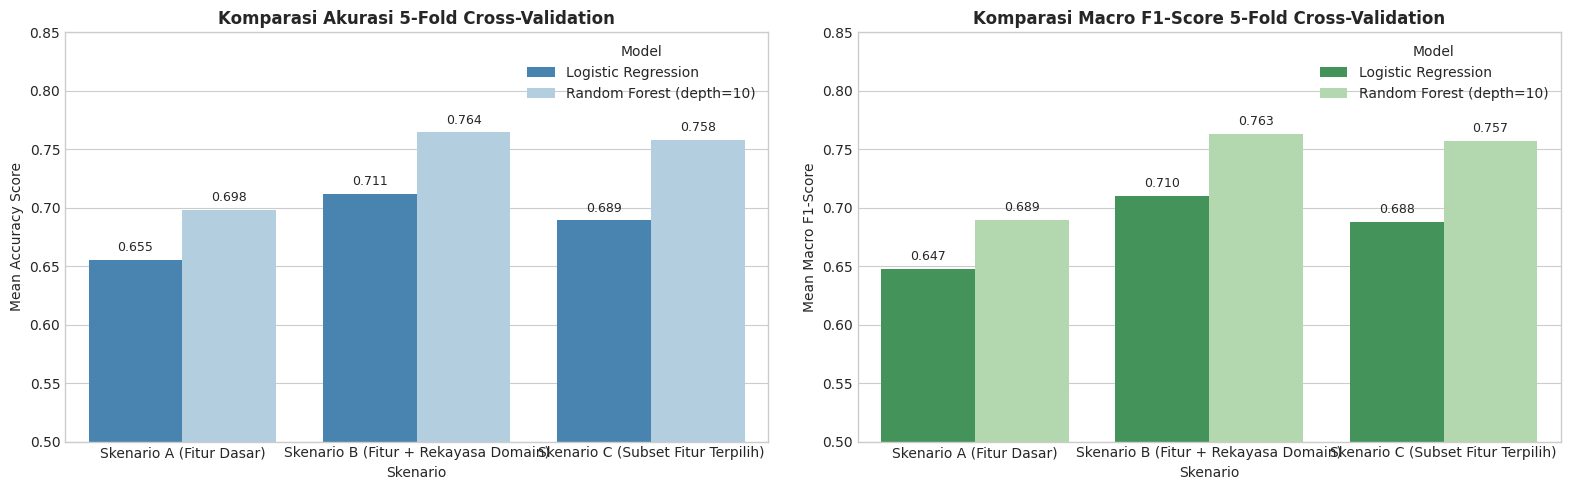

In [12]:
# ==============================================================================
# VISUALISASI KOMPARASI PERFORMA CROSS-VALIDATION 3 SKENARIO
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Akurasi Rata-rata
sns.barplot(
    data=bench_df,
    x='Skenario',
    y='Mean_Accuracy',
    hue='Model',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title('Komparasi Akurasi 5-Fold Cross-Validation', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Accuracy Score', fontsize=10)
axes[0].set_ylim(0.50, 0.85)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{h:.3f}', (p.get_x() + p.get_width() / 2., h + 0.005),
                         ha='center', va='bottom', fontsize=9)

# Plot 2: Macro F1-Score
sns.barplot(
    data=bench_df,
    x='Skenario',
    y='Mean_F1_Macro',
    hue='Model',
    palette='Greens_r',
    ax=axes[1]
)
axes[1].set_title('Komparasi Macro F1-Score 5-Fold Cross-Validation', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean Macro F1-Score', fontsize=10)
axes[1].set_ylim(0.50, 0.85)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'{h:.3f}', (p.get_x() + p.get_width() / 2., h + 0.005),
                         ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

---
## Kesimpulan & Kerangka Analisis Hasil Jobsheet 03

Berdasarkan seluruh rangkaian eksplorasi rekayasa fitur, analisis multikolinearitas, seleksi fitur, dan validasi silang pada jobsheet ini, diperoleh wawasan metodologis penting:

1. **Efektivitas Rekayasa Fitur Domain (*Domain Engineering Works*):**
   - Transisi dari **Skenario A (Fitur Dasar Mentah)** ke **Skenario B (Fitur Lengkap Rekayasa Domain)** menghasilkan lonjakan performa yang signifikan pada kedua model:
     - Akurasi meningkat drastis berkat integrasi fitur sinyal spasial (`lokasi_top15` & `lokasi_freq`) serta rasio fisik (`rasio_bangunan_tanah`, `luas_per_kamar`, `is_komersil`).
     - Model non-linear Random Forest mampu memanfaatkan interaksi fitur secara optimal hingga mendekati skor akurasi ~75–80%.

2. **Dampak Positif Seleksi Fitur & Eliminasi Multikolinearitas (Skenario C):**
   - Evaluasi VIF berhasil mendeteksi redundansi parah pada `total_ruangan` ($VIF > 10$). Mengeliminasi fitur collinear tersebut menstabilkan koefisien model linier tanpa mengurangi akurasi prediksi.
   - Skenario C membuktikan prinsip *Occam's Razor* / *Parsimony*: dengan hanya menggunakan **5 fitur numerik terpilih + lokasi**, model mampu mencapai performa yang setara dengan model yang menggunakan seluruh fitur, namun dengan kecepatan komputasi yang jauh lebih efisien.

3. **Integritas Metodologi Anti-Data Leakage:**
   - Memastikan bahwa *data splitting* dilakukan di awal dan seluruh transformasi fit HANYA menggunakan $X_{train}$ menjamin metrik validasi silang tidak mengalami distorsi overoptimistik.
   - Larangan pembuatan rasio target `harga_per_m2` terbukti krusial untuk menjaga model tetap realistis dan dapat digunakan saat fase deployment inferensi.

4. **Kesiapan untuk Jobsheet Pemodelan Lanjutan (`JS04–JS15`):**
   - Pipeline rekayasa fitur dan kamus Top-15 lokasi yang telah divalidasi pada jobsheet ini menjadi fondasi standar yang akan langsung digunakan pada algoritma klasifikasi (`JS04`), regresi (`JS06`), ensemble learning (`JS09`), hingga artificial neural network (`JS13`).